# Calibrating a score model to market probabilities

Prediction markets and bookmakers quote the probabilities of a home win, a
draw and an away win (1X2) for each match. Those three numbers say little
about the score, but a score model fitted to them can price the markets
that are not quoted: goal lines, handicaps, exact scores, all consistent with
the 1X2 prices.

This notebook fits the bivariate Poisson score model of the scores notebook to
1X2 probabilities by minimising the Kullback–Leibler divergence, then prices
derived markets. The functions used are those of
[`docs/examples/football_market_calibration.py`](../examples/football_market_calibration.py).

## 1. Theory

### From team strengths to 1X2

As in the scores notebook, home team $i$ and away team $j$ score Poisson goals
with rates $\lambda_{ij} = e^{\alpha_i - \delta_j + \eta/2}$ and
$\mu_{ij} = e^{\alpha_j - \delta_i - \eta/2}$, and the score matrix is
$P_{ij}(x, y) = p(x;\lambda_{ij})\,p(y;\mu_{ij})$. The model's 1X2 probabilities
are sums over regions of that matrix,

$$
\pi_{ij} = \Big(\sum_{x>y} P_{ij},\ \sum_{x=y} P_{ij},\ \sum_{x<y} P_{ij}\Big) .
$$

This is a non-linear map from two strengths per team to three probabilities
per match: the observable combines the two teams in a way no linear model
captures.

### Kullback–Leibler fit

With $q_{ij}$ the market probabilities, the fit minimises

$$
\sum_{(i,j)} \mathrm{KL}\left(q_{ij}\,\|\,\pi_{ij}(\theta)\right)
= \text{const} - \sum_{(i,j)} \sum_{o} q_{ij,o}\,\log \pi_{ij,o}(\theta),
$$

which is the multinomial likelihood (`maxlike.Finite`) with the probabilities
in place of counts. Newton's method uses the exact Hessian of this objective.
The probabilities are not counts, so the standard errors of such a fit are not
sampling errors; they only measure how well each parameter is pinned down,
in relative terms.

### Why the tail of the goal distribution matters

On a finite grid of $K = 8$ goals there are two ways to make the Poisson a
distribution:

- **censor**: the last cell is "7 or more", $p(7) = 1 - \sum_{k<7} p(k)$;
- **truncate**: condition on fewer than 8 goals, $p(k) / \sum_{k'<8} p(k')$.

With truncation, a very strong team can "win by a lot" with an absurd scoring
rate: all its mass piles up at 7 goals, which still counts as a win. The
market probabilities cannot rule that out, so the fit drifts there. Censoring
keeps the meaning of each cell and the problem disappears. Section 6 shows both.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps          # also puts the package and the examples on the path
from plot_style import BLUE, ORANGE, AQUA, TEXT_2
import maxlike
from maxlike.func import Poisson, Exp, Product, Linear, CollapseMatrix
import football_market_calibration as ex
import football_scores

ps.apply()

## 2. Data

For each match, the market probabilities of a home win (`1`), a draw (`0`) and
an away win (`-1`). They are gathered into an array
$q$[home, away, outcome]; a pair of teams that met twice adds up.

In [2]:
P, names, df = ex.load()
played = P.sum(-1) > 0
print(len(df), "matches,", played.sum(), "pairs of teams,", len(names), "teams")
df.head()

612 matches, 372 pairs of teams, 20 teams


,t1,t2,1,0,-1
0,0,11,0.059776,0.187489,0.752735
1,1,9,0.385355,0.305875,0.308770
2,2,15,0.812170,0.139874,0.047957
3,3,14,0.739289,0.178773,0.081938
4,4,12,0.424658,0.291016,0.284326


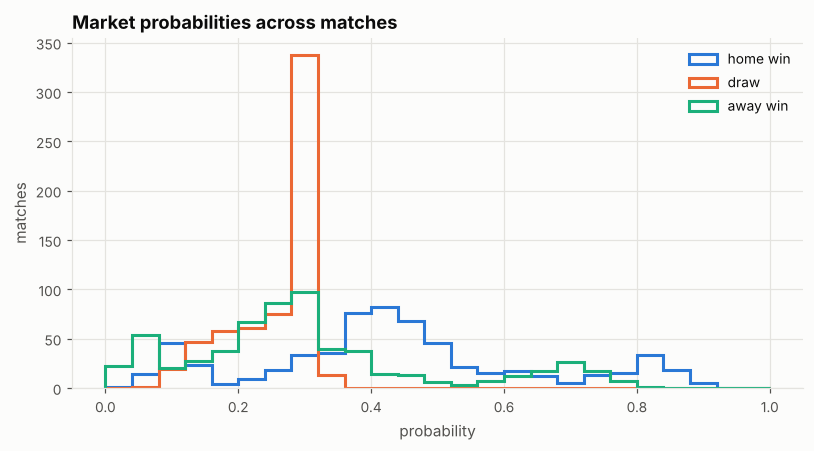

In [3]:
fig, ax = plt.subplots()
bins = np.linspace(0, 1, 26)
for col, label, color in zip(["1", "0", "-1"], ["home win", "draw", "away win"], [BLUE, ORANGE, AQUA]):
    ax.hist(df[col], bins=bins, histtype="step", lw=2, color=color, label=label)
ps.finish(ax, "Market probabilities across matches", "probability", "matches", legend=True)

Draws are priced in a narrow band (about 0.2 to 0.3); home and away wins span
almost the whole range.

## 3. Model and its graph

`CollapseMatrix()` turns the score matrix into 1X2 probabilities; the rest is
the score model of the scores notebook.

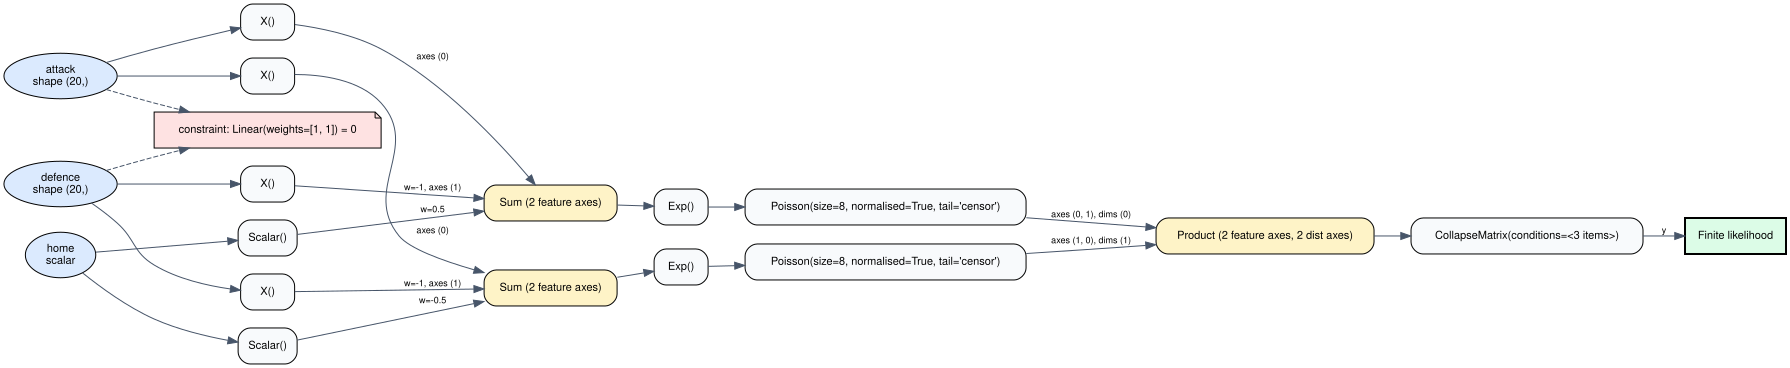

In [4]:
mle = ex.fit(P, names)
mle.graph()

## 4. How well the model reproduces the market

Each point is a pair of teams: market probability against model probability,
for the three outcomes.

largest gap per pair: mean 0.026, 99% quantile 0.083


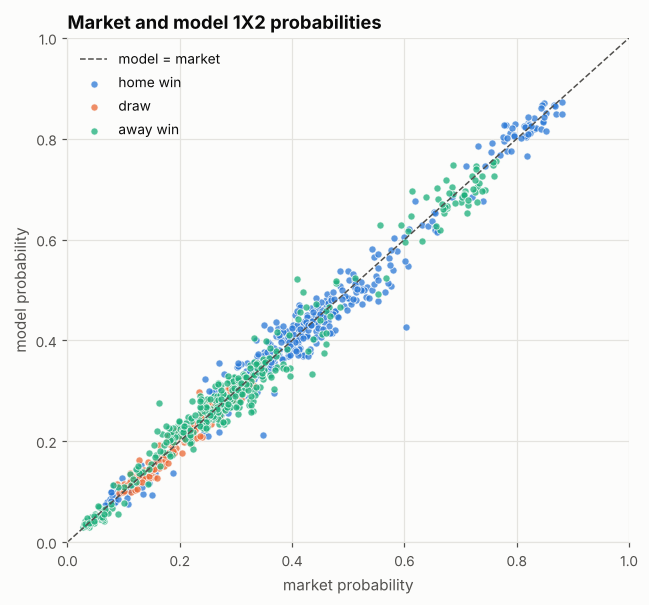

In [5]:
fitted = mle.predict()                                   # [home, away, 3]
market = P[played] / P[played].sum(-1, keepdims=True)
model = fitted[played]

fig, ax = plt.subplots(figsize=(6, 5.6))
ax.plot([0, 1], [0, 1], color=TEXT_2, lw=1, ls="--", label="model = market")
for k, (label, color) in enumerate(zip(["home win", "draw", "away win"], [BLUE, ORANGE, AQUA])):
    ax.scatter(market[:, k], model[:, k], s=22, color=color, alpha=0.75,
               edgecolor="#fcfcfb", linewidth=0.6, label=label)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ps.finish(ax, "Market and model 1X2 probabilities", "market probability",
          "model probability", legend=True)
err = np.abs(model - market).max(-1)
print("largest gap per pair: mean %.3f, 99%% quantile %.3f" % (err.mean(), np.quantile(err, .99)))

Two strengths per team and a home advantage, 41 parameters in all, reproduce
three probabilities for each of the 372 pairs. The remaining gaps are the part of the market prices
the model cannot represent (or noise in the prices).

**Team strengths.** Attack and defence on the log scale, as implied by the
market.

home advantage: 0.276


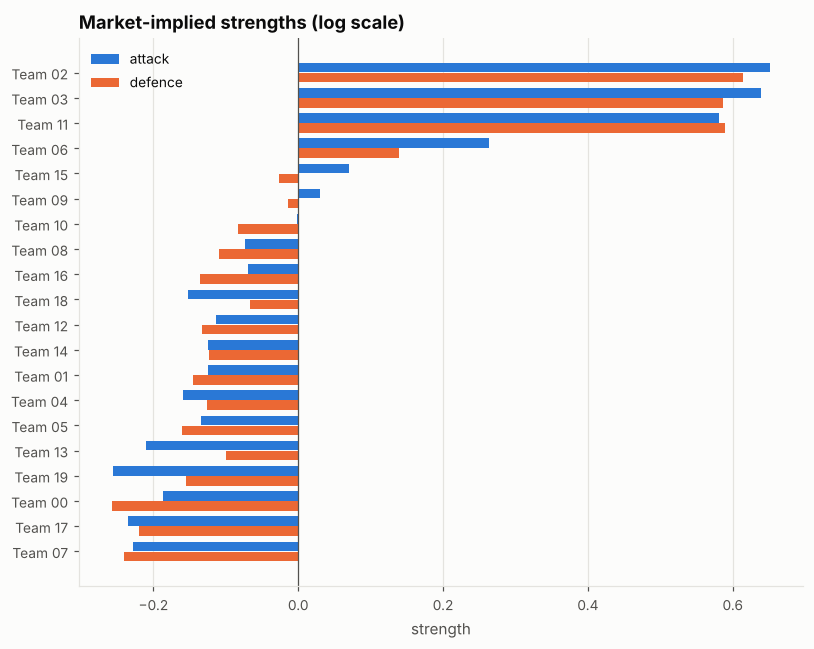

In [6]:
s = mle.summary()
table = pd.DataFrame({"attack": s.loc["attack", "estimate"],
                      "defence": s.loc["defence", "estimate"]})
table = table.loc[(table["attack"] + table["defence"]).sort_values().index]

fig, ax = plt.subplots(figsize=(7.5, 6))
yy = np.arange(len(table))
ax.barh(yy + 0.2, table["attack"], 0.38, color=BLUE, label="attack")
ax.barh(yy - 0.2, table["defence"], 0.38, color=ORANGE, label="defence")
ax.set_yticks(yy); ax.set_yticklabels(table.index)
ax.axvline(0, color=TEXT_2, lw=0.8)
ax.grid(axis="y", visible=False)
ps.finish(ax, "Market-implied strengths (log scale)", "strength", None, legend=True)
print("home advantage: %.3f" % s.loc[("home", ""), "estimate"])

## 5. Pricing markets that are not quoted

For the first match of the data: the full score matrix, then the probability
of more than $L$ goals for each line and of a home win by more than $h$ goals
for each handicap. One set of parameters prices them all.

Team 00 (home) v Team 11
market 1X2: 0.085 / 0.194 / 0.721
model  1X2: 0.086 / 0.188 / 0.726


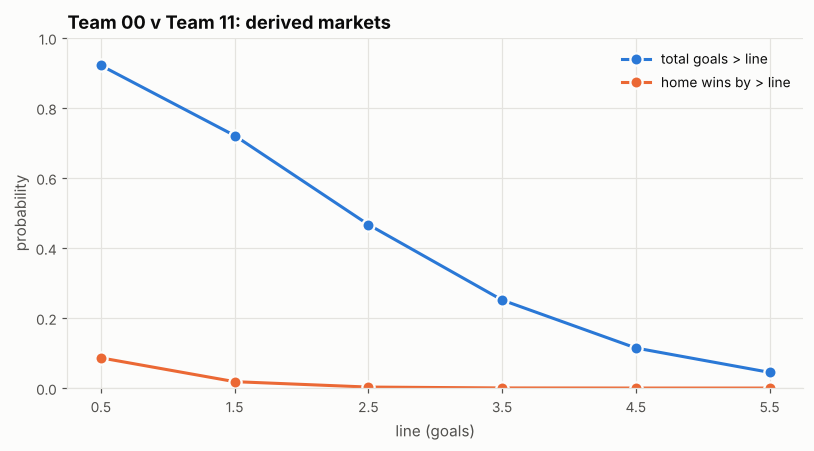

In [7]:
row = df.iloc[0]
i, j = int(row.t1), int(row.t2)
scores = football_scores.score_model()
print("%s (home) v %s" % (names[i], names[j]))
print("market 1X2: %.3f / %.3f / %.3f" % tuple(P[i, j] / P[i, j].sum()))
print("model  1X2: %.3f / %.3f / %.3f" % tuple(fitted[i, j]))

lines = np.arange(0.5, 6.5, 1.0)
over = [mle.predict(CollapseMatrix([(1, 1, -L, 1)]) @ scores)[i, j, 0] for L in lines]
margin = [mle.predict(CollapseMatrix([(1, -1, -h, 1)]) @ scores)[i, j, 0] for h in lines]

fig, ax = plt.subplots()
ax.plot(lines, over, "o-", color=BLUE, markersize=8, markeredgecolor="#fcfcfb",
        markeredgewidth=1.5, label="total goals > line")
ax.plot(lines, margin, "o-", color=ORANGE, markersize=8, markeredgecolor="#fcfcfb",
        markeredgewidth=1.5, label="home wins by > line")
ax.set_xticks(lines); ax.set_ylim(0, 1)
ps.finish(ax, "%s v %s: derived markets" % (names[i], names[j]), "line (goals)",
          "probability", legend=True)

## 6. Censored or truncated tail

The same fit with a truncated goal distribution. The 1X2 fit is close, but the
scoring rates it implies are not: some pairs get rates of tens or hundreds of
goals a match.

censor   mean log-probability of the market outcomes -0.9656, rates from 0.48 to 2.8
truncate mean log-probability of the market outcomes -0.9719, rates from 0.58 to 186.5


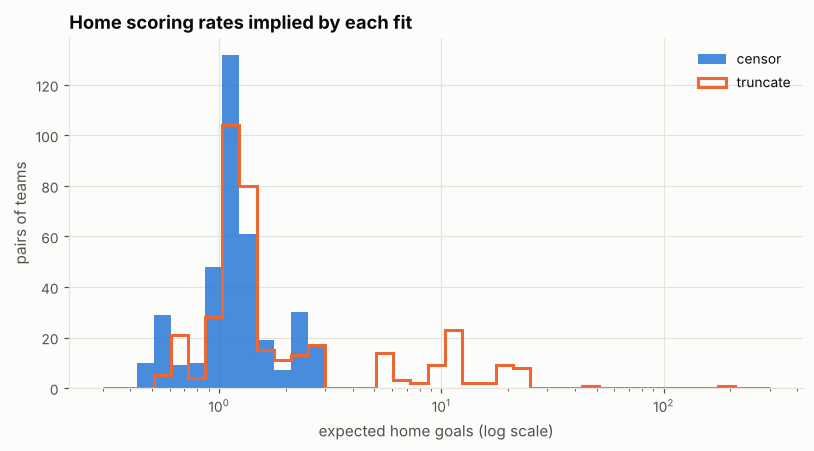

In [8]:
def score_model(tail, size=football_scores.MAX_GOALS):
    home_rate, away_rate = football_scores.rates()
    goals = Poisson(size, normalised=True, tail=tail)
    score = Product(2, 2)
    score.add(goals @ Exp() @ home_rate, [0, 1, 2], [0, 1], 0)
    score.add(goals @ Exp() @ away_rate, [0, 1, 2], [1, 0], 1)
    return score


rates = {}
for tail in ["censor", "truncate"]:
    m = maxlike.Finite()
    m.model = CollapseMatrix() @ score_model(tail)
    m.add_constraint([0, 1], Linear([1, 1]))
    m.add_param(pd.Series(0., index=names), name="attack")
    m.add_param(pd.Series(0., index=names), name="defence")
    m.add_param(0., name="home")
    m.fit(N=P)
    a, d, h = [np.ma.getdata(p) for p in m.get_params()]
    rates[tail] = np.exp(a[:, None] - d[None, :] + h / 2)[played]
    p = m.predict()[played]
    print("%-8s mean log-probability of the market outcomes %.4f, rates from %.2f to %.1f" % (
        tail, (market * np.log(p)).sum(-1).mean(), rates[tail].min(), rates[tail].max()))

fig, ax = plt.subplots()
bins = np.logspace(np.log10(0.3), np.log10(300), 40)
ax.hist(rates["censor"], bins=bins, color=BLUE, alpha=0.85, label="censor")
ax.hist(rates["truncate"], bins=bins, histtype="step", lw=2, color=ORANGE, label="truncate")
ax.set_xscale("log")
ps.finish(ax, "Home scoring rates implied by each fit", "expected home goals (log scale)",
          "pairs of teams", legend=True)

The censored fit keeps every rate in a plausible range (0.5 to 3 goals) and
matches the market better. A truncated fit would need a much wider grid to
behave; censoring gets there with 8 goals.